In [ ]:
# !pip install sentence-transformers

In [6]:
import json
import re
from datetime import datetime, timezone
from pathlib import Path
import requests

In [3]:
def extract_events_with_ollama(prompt, model="llama3.2"):

    response = requests.post(
        "http://localhost:11434/api/generate",
        json={"model": model, "prompt": prompt, "stream": False}
    )
    
    return response.json()["response"]


def parse_salient_events(llm_output):
    events = []
    for line in llm_output.strip().splitlines():
        if not line.strip():
            continue

        # If line starts with "Salient event" keep text after first colon
        if ":" in line and line.lower().startswith("salient event"):
            description = line.split(":", 1)[1].strip()
        else:
            # remove leading "Salient event X" if present (with optional punctuation)
            description = re.sub(r"^\s*Salient event\s*\d+\s*[:\.\)\-]*\s*", "", line, flags=re.I)

            # remove leading numeric list markers like "1. ", "1) ", "1 - "
            description = re.sub(r"^\s*\d+\s*[:\.\)\-]*\s*", "", description)

        if description:
            events.append(description)
    return events

def save_generated_annotation(events, prompt, file_path="generated_annotations_trials.txt"):

    file_path = Path(file_path)

    text = "\n".join(events) if isinstance(events, list) else str(events)

    record = {
        "timestamp_saved": datetime.now(timezone.utc).isoformat(),
        "prompt": prompt,
        "annotation": text
    }
    with file_path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n\n")

    return record

In [4]:
vlm_description = """The video starts with a person walking down a street in a city, passing by various buildings and shops. The scene then transitions to a person sitting on the ground, wearing earphones and looking at something in their hands. The next scene shows a group of people gathered around a banner, with one person holding a microphone. The video then shows a group of people standing on a beach, with a large building in the background. The final scene shows a person lying on a bed, holding a camera."""
prompt = f"""You are an expert video annotator. Below is a description of a video.
Understand the overall context and narrative of the video based on the description provided.
Extract between 4 and 10 salient events from this description.

A salient event is important for understanding the overall narrative, clearly distinguishable, and described in 1-2 concise sentences. Don't narrate the flow of the video, just describe the events.

Format EXACTLY like this:
Salient event 1: [description]
Salient event 2: [description]
...
Only output the numbered list, nothing else.

Video description:
{vlm_description}"""

In [7]:
result = extract_events_with_ollama(prompt)
print(result)

events = parse_salient_events(result)
print("\n--- Parsed Events ---")
for i, event in enumerate(events, 1):
    print(f"{event}")

save_generated_annotation(events, prompt=prompt)

1: A person is seen walking down a street in a city, passing by various buildings and shops.
2: A person sits on the ground, wearing earphones and looking at something in their hands.
3: A group of people gather around a banner with one person holding a microphone.
4: The scene cuts to a group of people standing on a beach, with a large building in the background.
5: A person lies on a bed, holding a camera.

--- Parsed Events ---
A person is seen walking down a street in a city, passing by various buildings and shops.
A person sits on the ground, wearing earphones and looking at something in their hands.
A group of people gather around a banner with one person holding a microphone.
The scene cuts to a group of people standing on a beach, with a large building in the background.
A person lies on a bed, holding a camera.


{'timestamp_saved': '2026-05-11T00:25:51.142270+00:00',
 'prompt': "You are an expert video annotator. Below is a description of a video.\nUnderstand the overall context and narrative of the video based on the description provided.\nExtract between 4 and 10 salient events from this description.\n\nA salient event is important for understanding the overall narrative, clearly distinguishable, and described in 1-2 concise sentences. Don't narrate the flow of the video, just describe the events.\n\nFormat EXACTLY like this:\nSalient event 1: [description]\nSalient event 2: [description]\n...\nOnly output the numbered list, nothing else.\n\nVideo description:\nThe video starts with a person walking down a street in a city, passing by various buildings and shops. The scene then transitions to a person sitting on the ground, wearing earphones and looking at something in their hands. The next scene shows a group of people gathered around a banner, with one person holding a microphone. The vide

In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Load a small but good embedding model — no API key needed
embedder = SentenceTransformer("all-MiniLM-L6-v2")  # ~80MB, downloads once

# ── Your annotations ──────────────────────────────────────────────
human_annotations = [
    "A person walks down a city street passing shops and buildings",
    "Someone sits on the ground wearing earphones looking at their hands",
    "A group gathers around a banner while someone holds a microphone",
    "People stand on a beach with a large building in the background",
    "A person lies on a bed holding a camera",
]

# ── Generated events (from your pipeline) ─────────────────────────
generated_events = events  # the list from parse_salient_events()


# ── Compute embeddings ─────────────────────────────────────────────
human_embeddings    = embedder.encode(human_annotations)
generated_embeddings = embedder.encode(generated_events)

# ── Compare every human annotation vs every generated event ───────
similarity_matrix = cosine_similarity(human_embeddings, generated_embeddings)

# ── Report ────────────────────────────────────────────────────────
THRESHOLD = 0.5  # tune this — 0.5 is a reasonable starting point

print("=== Per-annotation results ===\n")
detected = 0
for i, human_event in enumerate(human_annotations):
    best_score = similarity_matrix[i].max()
    best_match_idx = similarity_matrix[i].argmax()
    best_match = generated_events[best_match_idx]
    is_detected = best_score >= THRESHOLD

    if is_detected:
        detected += 1

    status = "DETECTED" if is_detected else "MISSED"
    print(f"{status} (score: {best_score:.2f})")
    print(f"  Human:     {human_event}")
    print(f"  Best match: {best_match}\n")

print("=== Summary ===")
print(f"Detected:  {detected} / {len(human_annotations)}")
print(f"Missed:    {len(human_annotations) - detected} / {len(human_annotations)}")
print(f"Recall:    {detected / len(human_annotations):.1%}")
print(f"Avg similarity (all pairs): {similarity_matrix.max(axis=1).mean():.2f}")

c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Boop\anaconda3\envs\python3-9\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Boop\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In 

=== Per-annotation results ===

✅ DETECTED (score: 0.93)
  Human:     A person walks down a city street passing shops and buildings
  Best match: A person is seen walking down a street in a city, passing by various buildings and shops.

✅ DETECTED (score: 0.95)
  Human:     Someone sits on the ground wearing earphones looking at their hands
  Best match: A person sits on the ground, wearing earphones and looking at something in their hands.

✅ DETECTED (score: 0.96)
  Human:     A group gathers around a banner while someone holds a microphone
  Best match: A group of people gather around a banner with one person holding a microphone.

✅ DETECTED (score: 0.80)
  Human:     People stand on a beach with a large building in the background
  Best match: The scene cuts to a group of people standing on a beach, with a large building in the background.

✅ DETECTED (score: 0.99)
  Human:     A person lies on a bed holding a camera
  Best match: A person lies on a bed, holding a camera.

=== Sum

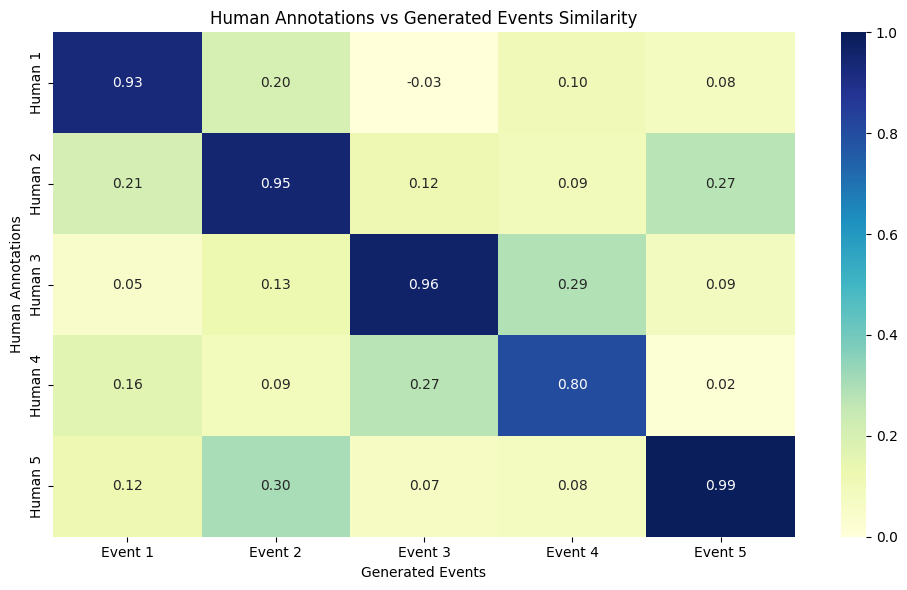

In [12]:
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

sim_df = pd.DataFrame(
    similarity_matrix,
    index=[f"Human {i+1}" for i in range(len(human_annotations))],
    columns=[f"Event {i+1}" for i in range(len(generated_events))]
)

plt.figure(figsize=(10, 6))
sns.heatmap(sim_df, annot=True, cmap="YlGnBu", vmin=0, vmax=1, fmt=".2f")
plt.title("Human Annotations vs Generated Events Similarity")
plt.xlabel("Generated Events")
plt.ylabel("Human Annotations")
plt.tight_layout()
plt.show()